# What Makes People Live Longer?
## Predicting Life Expectancy from Development Indicators

The notebook follows the CRISP-DM process:

1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Further Data Understanding after Preparation
5. Modeling
6. Evaluation


## 1. Business Understanding

Life expectancy at birth differs strongly between countries. This project tries to examine which development indicators go along with a long life, and how well they can predict the life expectancy of a country.

Questions:
1. Which indicators are most important for predicting life expectancy, and how do they influence the prediction?
2. What surprising insights can be found, for example countries that live much longer or shorter than predicted?
3. How accurately can a model predict the life expectancy of a country?
4. What would the model predict if every country with low access to electricity had full access?



## 2. Data Understanding

### 2.1 Gather: import libraries and load the data

Data source: World Bank DataBank, World Development Indicators (WDI), download WDI_CSV.zip, extracted into the folder data/WDI_CSV/.

Files used:
- WDICSV.csv: values of all indicators for all countries and years
- WDICountry.csv: information about each country
- WDISeries.csv: information about each indicator

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

%matplotlib inline

In [2]:
# Load the three files
data_folder = 'data/WDI_CSV/'
df_values = pd.read_csv(data_folder + 'WDICSV.csv')
df_countries = pd.read_csv(data_folder + 'WDICountry.csv')
df_series = pd.read_csv(data_folder + 'WDISeries.csv')

### 2.2 First look at the three files

#### Values file

In [3]:
# Number of rows and columns
print('Values file:', df_values.shape)
print('Country file:', df_countries.shape)
print('Indicator file:', df_series.shape)

Values file: (398468, 70)
Country file: (265, 31)
Indicator file: (1498, 20)


In [4]:
df_values.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,18.471500,18.822373,19.302882,19.770426,20.120927,20.440680,20.817895,21.161010,21.532841,NaN
1,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.RU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,7.682625,7.953281,8.528101,8.878267,9.050266,9.111884,9.285654,9.403676,9.687390,NaN
2,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.UR.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,39.163151,39.206303,39.406216,39.569413,39.958115,40.025590,40.203585,40.728295,41.118943,NaN
3,Africa Eastern and Southern,AFE,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,38.859598,40.223744,43.035073,44.390861,46.282371,48.127211,48.742043,50.667516,52.598171,NaN
4,Africa Eastern and Southern,AFE,"Access to electricity, rural (% of rural popul...",EG.ELC.ACCS.RU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,24.584906,25.375037,26.941984,28.983183,30.909991,32.709837,33.998179,35.240236,36.080572,NaN


In [5]:
#Columns data types and number of non-missing values
df_values.info()

<class 'pandas.DataFrame'>
RangeIndex: 398468 entries, 0 to 398467
Data columns (total 70 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Country Name    398468 non-null  str    
 1   Country Code    398468 non-null  str    
 2   Indicator Name  398468 non-null  str    
 3   Indicator Code  398468 non-null  str    
 4   1960            37345 non-null   float64
 5   1961            42695 non-null   float64
 6   1962            43999 non-null   float64
 7   1963            44933 non-null   float64
 8   1964            45431 non-null   float64
 9   1965            47249 non-null   float64
 10  1966            47508 non-null   float64
 11  1967            48148 non-null   float64
 12  1968            48774 non-null   float64
 13  1969            49549 non-null   float64
 14  1970            72138 non-null   float64
 15  1971            76457 non-null   float64
 16  1972            78160 non-null   float64
 17  1973            78813

In [6]:
# Number of different countries and indicators
print('Countries/areas:', df_values['Country Code'].nunique())
print('Indicators:', df_values['Indicator Code'].nunique())

Countries/areas: 266
Indicators: 1498


- Each row is one country and one indicator, the years are columns.
- Almost 400k rows, about 270 countries/areas and almost 1,500 indicators.
- Many values are missing, especially in the early years and in 2025.

#### Country file

In [7]:
df_countries.head()

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,NaN,Latin America & Caribbean,High income,AW,...,NaN,Enhanced General Data Dissemination System (e-...,2020 (expected),NaN,NaN,Yes,NaN,NaN,2018.0,NaN
1,AFE,Africa Eastern and Southern,Africa Eastern and Southern,Africa Eastern and Southern,ZH,NaN,"26 countries, stretching from the Red Sea in t...",NaN,NaN,ZH,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,The reporting period for national accounts dat...,Middle East & North Africa,Low income,AF,...,Consolidated central government,Enhanced General Data Dissemination System (e-...,1979,Multiple Indicator Cluster Survey 2022-2023,"Integrated household survey (IHS), 2016/17",NaN,2003.0,NaN,2018.0,NaN
3,AFW,Africa Western and Central,Africa Western and Central,Africa Western and Central,ZI,NaN,"22 countries, stretching from the westernmost ...",NaN,NaN,ZI,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,The World Bank systematically assesses the app...,Sub-Saharan Africa,Lower middle income,AO,...,Budgetary central government,Enhanced General Data Dissemination System (e-...,2014,Inquérito de Indicadores Múltiplos e de Saúde ...,"Integrated household survey (IHS), 2008/09",NaN,2023.0,NaN,2018.0,NaN


In [8]:
df_countries.info()

<class 'pandas.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 31 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Country Code                                       265 non-null    str    
 1   Short Name                                         265 non-null    str    
 2   Table Name                                         265 non-null    str    
 3   Long Name                                          265 non-null    str    
 4   2-alpha code                                       263 non-null    str    
 5   Currency Unit                                      217 non-null    str    
 6   Special Notes                                      135 non-null    str    
 7   Region                                             217 non-null    str    
 8   Income Group                                       217 non-null    str    
 9   WB-2 code            

- One row per country with its region.
- About 50 entries have no region.

#### Indicator file

In [9]:
df_series.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,Limitations and exceptions,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type
0,AG.CON.FERT.PT.ZS,Environment: Agricultural production,Fertilizer consumption (% of fertilizer produc...,Fertilizer consumption measures the quantity o...,Fertilizer consumption measures the quantity o...,% (ratio),Annual,NaN,The world and regional aggregate series do not...,Weighted average,The FAO has revised the time series for fertil...,NaN,NaN,"FAO electronic files and web site, Food and Ag...",Methodology: Fertilizer consumption measures t...,"Factors, such as the green revolution, have le...",NaN,NaN,NaN,CC BY-4.0
1,AG.CON.FERT.ZS,Environment: Agricultural production,Fertilizer consumption (kilograms per hectare ...,Fertilizer consumption measures the quantity o...,Fertilizer consumption measures the quantity o...,kg per hectare of arable land,Annual,NaN,The world and regional aggregate series do not...,Weighted average,The FAO has revised the time series for fertil...,NaN,NaN,"FAO electronic files and web site, Food and Ag...",Methodology: Fertilizer consumption measures t...,"Factors, such as the green revolution, have le...",NaN,NaN,NaN,CC BY-4.0
2,AG.LND.AGRI.K2,Environment: Land use,Agricultural land (sq. km),Agricultural land refers to the land area that...,Agricultural land refers to the land area that...,square kilometers (sq. km),Annual,NaN,Areas of former states are included in the suc...,Sum,The data are collected by the Food and Agricul...,NaN,NaN,"FAO electronic files and web site, Food and Ag...",Methodology: Agricultural land constitutes onl...,Agricultural land covers more than one-third o...,NaN,NaN,NaN,CC BY-4.0
3,AG.LND.AGRI.ZS,Environment: Land use,Agricultural land (% of land area),Agricultural land refers to the share of land ...,Agricultural land refers to the share of land ...,% (share) of land area,Annual,NaN,Areas of former states are included in the suc...,Weighted average,The data are collected by the Food and Agricul...,NaN,NaN,"FAO electronic files and web site, Food and Ag...",Methodology: Agriculture is still a major sect...,Agricultural land covers more than one-third o...,NaN,NaN,NaN,CC BY-4.0
4,AG.LND.ARBL.HA,Environment: Land use,Arable land (hectares),Arable land (in hectares) includes land define...,Arable land (in hectares) includes land define...,hectares,Annual,NaN,Areas of former states are included in the suc...,NaN,The Food and Agriculture Organization (FAO) tr...,NaN,NaN,"FAO electronic files and web site, Food and Ag...",Methodology: Temporary fallow land refers to l...,Agricultural land covers more than one-third o...,NaN,NaN,NaN,CC BY-4.0


In [10]:
df_series.info()

<class 'pandas.DataFrame'>
RangeIndex: 1498 entries, 0 to 1497
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Series Code                          1498 non-null   str    
 1   Topic                                1498 non-null   str    
 2   Indicator Name                       1498 non-null   str    
 3   Short definition                     1498 non-null   str    
 4   Long definition                      1498 non-null   str    
 5   Unit of measure                      1196 non-null   str    
 6   Periodicity                          1460 non-null   str    
 7   Base Period                          0 non-null      float64
 8   Other notes                          344 non-null    str    
 9   Aggregation method                   1128 non-null   str    
 10  Limitations and exceptions           892 non-null    str    
 11  Notes from original source           6 no

- One row per indicator.
- The column topic puts every indicator into a group (for example "Environment: Land use") These groups help to find indicators that should not be used.

### 2.3 Real countries vs. groups of countries

Which entries have no region?

In [11]:
#Entries without a region
no_region = df_countries[df_countries['Region'].isna()]
print('Entries without a region:', len(no_region))
print(no_region['Table Name'])

Entries without a region: 48
1                            Africa Eastern and Southern
3                             Africa Western and Central
7                                             Arab World
36                        Central Europe and the Baltics
49                                Caribbean small states
61           East Asia & Pacific (excluding high income)
62                            Early-demographic dividend
63                                   East Asia & Pacific
64         Europe & Central Asia (excluding high income)
65                                 Europe & Central Asia
68                                             Euro area
73                                        European Union
74     Fragility, Conflict, and Violence (FCV) situat...
95                                           High income
98                Heavily indebted poor countries (HIPC)
102                                            IBRD only
103                                     IDA & IBRD total
10

- The entries without a region are groups of countries like "World", "European Union" and not real countries.
-> Only the 217 real countries are kept.

In [12]:
# Keep only the real countries
df_countries_real = df_countries[df_countries['Region'].notna()].copy()
print('Real countries:', len(df_countries_real))

# Keep only the rows of real countries in the values file
is_real = df_values['Country Code'].isin(df_countries_real['Country Code'])
df_values_real = df_values[is_real].copy()
print('Rows (country x indicator):', len(df_values_real))

Real countries: 217
Rows (country x indicator): 325066


### 2.4 Target variable: life expectancy in 2024

In [13]:
# Life expectancy at birth (years) in 2024
life_exp = df_values_real[df_values_real['Indicator Code'] == 'SP.DYN.LE00.IN']
life_exp = life_exp.set_index('Country Code')['2024']

print('Countries with a value:', life_exp.notna().sum())
life_exp.describe().round(1)

Countries with a value: 217


count    217.0
mean      74.0
std        7.1
min       54.6
25%       68.7
50%       74.7
75%       79.8
max       86.5
Name: 2024, dtype: float64

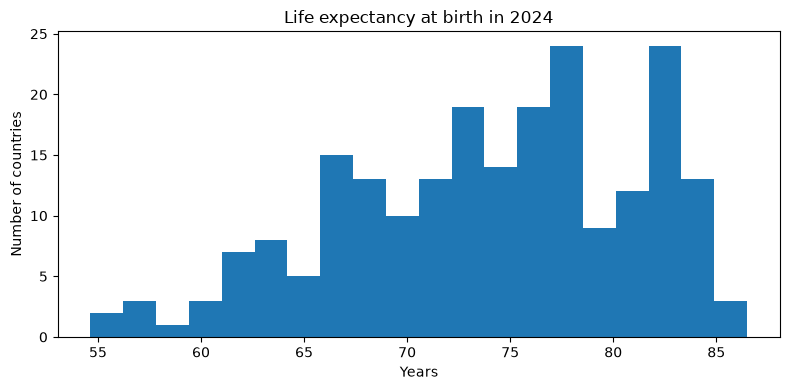

In [14]:
# Histogram of life expectancy
plt.figure(figsize=(8, 4))
plt.hist(life_exp, bins=20)
plt.title('Life expectancy at birth in 2024')
plt.xlabel('Years')
plt.ylabel('Number of countries')
plt.tight_layout()
plt.show()

Observation:
- Life expectancy is available for all countries.
- It ranges from about 55 to 86 years, so there is a gap of more than 30 years between countries. Most countries are between 65 and 85 years.

### 2.5 Which indicator groups (topics) exist?

The column Topic has the form "main topic: sub topic".

In [15]:
# Main topic = text before the colon
df_series['Main Topic'] = df_series['Topic'].str.split(':').str[0]
print(df_series['Main Topic'].value_counts())

Main Topic
Economic Policy & Debt       360
Health                       251
Social Protection & Labor    169
Education                    156
Private Sector & Trade       151
Environment                  144
Public Sector                 99
Financial Sector              55
Infrastructure                36
Trade                         24
Poverty                       24
Gender                        17
Policy & institutions         12
Name: count, dtype: int64


In [16]:
# Sub topics of the main topic Health
health = df_series[df_series['Main Topic'] == 'Health']
print(health['Topic'].value_counts())

Topic
Health: Population: Structure        58
Health: Mortality                    39
Health: Risk factors                 33
Health: Nutrition                    30
Health: Disease prevention           27
Health: Health systems               23
Health: Reproductive health          16
Health: Population: Dynamics         13
Health: Universal Health Coverage    10
Health                                2
Name: count, dtype: int64


In [17]:
# Topic of the target indicator
is_target = df_series['Series Code'] == 'SP.DYN.LE00.IN'
df_series[is_target][['Series Code', 'Topic', 'Indicator Name']]

,Series Code,Topic,Indicator Name
1318,SP.DYN.LE00.IN,Health: Mortality,"Life expectancy at birth, total (years)"


Observation:
- Health is the second largest topic with about 250 indicators.
- Life expectancy itself belongs to Health: Mortality.

### 2.6 Data leakage check

Some indicators could give away the answer, because they are part of life expectancy or a direct result of it. Which indicators belong to the mortality and population topics?

In [18]:
# indicators of the mortality and population topics 
leakage_topics = ['Health: Mortality',
                  'Health: Population: Structure',
                  'Health: Population: Dynamics']

for topic in leakage_topics:
    names = df_series[df_series['Topic'] == topic]['Indicator Name']
    print(topic, '-', len(names), 'indicators')
    print(names.head(8).to_string(index=False))
    print()

Health: Mortality - 39 indicators
                   Number of deaths ages 5-9 years
                 Number of deaths ages 10-14 years
                 Number of deaths ages 15-19 years
                 Number of deaths ages 20-24 years
                           Number of infant deaths
                       Number of under-five deaths
                         Number of neonatal deaths
Probability of dying among children ages 5-9 ye...

Health: Population: Structure - 58 indicators
Population ages 00-04, female (% of female popu...
Population ages 00-04, male (% of male population)
                      Population ages 0-14, female
Population ages 0-14, female (% of female popul...
                        Population ages 0-14, male
 Population ages 0-14, male (% of male population)
                       Population ages 0-14, total
      Population ages 0-14 (% of total population)

Health: Population: Dynamics - 13 indicators
              Birth rate, crude (per 1,000 people)
      

Observation:
- Health: Mortality contains numbers of deaths and the probability of dying at different ages. Life expectancy is calculated from exactly these values, and it is part of this topic itself (section 2.5).
- Health: Population: Structure contains the population by age group, for example the share of children. How old a population is follows from how long people live.
- Health: Population: Dynamics contains birth and death rates and age dependency ratios, which are also closely linked to how long people live. 

Decision:
- These three topics are removed.

The topic Public Sector also contains the Human capital index plus, which has a health part. What does it measure?

In [19]:
# Indicators of the Human capital index plus
# and the definition of the health pillar
names = df_series['Indicator Name']
hci = df_series[names.str.contains('Human capital index', regex=False)]
print(hci[['Series Code', 'Topic']])
print()
print(hci[hci['Series Code'] == 'HD_HCIP_HLTH_TO']['Long definition'].iloc[0])

         Series Code                                 Topic
414  HD_HCIP_EDUC_FE  Public Sector: Policy & institutions
415  HD_HCIP_EDUC_MA  Public Sector: Policy & institutions
416  HD_HCIP_EDUC_TO  Public Sector: Policy & institutions
417  HD_HCIP_HLTH_FE  Public Sector: Policy & institutions
418  HD_HCIP_HLTH_MA  Public Sector: Policy & institutions
419  HD_HCIP_HLTH_TO  Public Sector: Policy & institutions
420  HD_HCIP_OTJL_FE  Public Sector: Policy & institutions
421  HD_HCIP_OTJL_MA  Public Sector: Policy & institutions
422  HD_HCIP_OTJL_TO  Public Sector: Policy & institutions
423  HD_HCIP_OVRL_FE  Public Sector: Policy & institutions
424  HD_HCIP_OVRL_MA  Public Sector: Policy & institutions
425  HD_HCIP_OVRL_TO  Public Sector: Policy & institutions

The human capital index plus (HCI+): health pillar score captures productivity effects of surviving to working age and achieving adequate early-life physical growth.


Observation:
- The health part of this index measures survival to working age, which is part of life expectancy.

Decision:
- All indicators of the Human capital index are removed.

### 2.7 Summary of the Data Understanding

- Only real countries are used.
- Life expectancy is available for all of them and differs by more than 30 years.
- The newest years are incomplete.
- Mortality, population and Human capital index indicators are removed to avoid data leakage.

## 3. Data Preparation

### 3.1 Remove indicators

Two rules:
1. Data leakage (section 2.6): indicators of the topics Health: Mortality, Health: Population: Structure and Health: Population: Dynamics, and the Human capital index plus.
2. Indicators for sub-groups of the population.

In [20]:
# remove the leakage topics 
leakage_topics = ['Health: Mortality',
                  'Health: Population: Structure',
                  'Health: Population: Dynamics']
is_hci = df_series['Indicator Name'].str.contains('Human capital index',
                                                  regex=False)
is_leakage = df_series['Topic'].isin(leakage_topics) | is_hci

df_series_keep = df_series[~is_leakage].copy()
print('Indicators removed:', is_leakage.sum())
print('Indicators left:', len(df_series_keep))

Indicators removed: 122
Indicators left: 1376


Example for sub-groups: 

In [21]:
names = df_series_keep['Indicator Name']
names[names.str.contains('Access to electricity')]

208    Access to electricity, rural (% of rural popul...
209    Access to electricity, urban (% of urban popul...
210              Access to electricity (% of population)
Name: Indicator Name, dtype: str

- Besides the total there are versions for rural and urban areas (and for women and men). They mostly repeat the total.

Decision: Only the totals are kept.

In [22]:
# Rule 2: remove indicators for sub-groups
subgroup_words = [', female', ', male', ', rural', ', urban']

is_subgroup = pd.Series(False, index=df_series_keep.index)
for word in subgroup_words:
    names = df_series_keep['Indicator Name']
    is_subgroup = is_subgroup | names.str.contains(word, regex=False)

df_series_keep = df_series_keep[~is_subgroup]
print('Indicators removed:', is_subgroup.sum())
print('Indicators left:', len(df_series_keep))

Indicators removed: 190
Indicators left: 1186


### 3.2 Create one table with the most recent values

Many values are missing in the newest years (see above). So for each country and indicator the most recent value from 2020 to 2024 is used. if 2024 is missing, 2023 is used, and so on. 2025 is left out because it is still too empty. The target stays life expectancy in 2024.

In [23]:
#values of the remaining indicators
is_kept = df_values_real['Indicator Code'].isin(df_series_keep['Series Code'])
df_values_keep = df_values_real[is_kept]

# Start with 2020, newer years overwrite the older values where they exist
df = df_values_keep.pivot(index='Country Code', columns='Indicator Code',
                          values='2020')
for year in ['2021', '2022', '2023', '2024']:
    newer = df_values_keep.pivot(index='Country Code',
                                 columns='Indicator Code', values=year)
    df = newer.fillna(df)

indicator_columns = df.columns

In [24]:
# compare indicators with a value for at least 90 % of the countries
only_2024 = df_values_keep.pivot(index='Country Code',
                                 columns='Indicator Code', values='2024')
print('Only 2024:', (only_2024.notna().mean() >= 0.9).sum())
print('Most recent value 2020-2024:', (df.notna().mean() >= 0.9).sum())

Only 2024: 108
Most recent value 2020-2024: 193


- Using older values when 2024 is missing makes many more indicators usable (about 190 instead of about 110).
- The most recent value from 2020 to 2024 is used. Most indicators change only slowly.

In [25]:
# Add the target (life expectancy in 2024)
df['life_expectancy'] = life_exp
print('Shape:', df.shape)

Shape: (217, 1187)


### 3.3 Selection of the indicators

1. Try to keep only indicators that exist for at least 90 % of the countries, otherwise too many countries would be lost.
2. keep the 30 indicators most strongly related to life expectancy.

In [26]:
# all indicators with a value for at least 90 % of the countries
coverage = df[indicator_columns].notna().mean()
columns = list(coverage[coverage >= 0.9].index)
print('Indicators with at least 90 %:', len(columns))

# the 30 indicators with the strongest correlation with the target
corr_table = df[columns + ['life_expectancy']].corr()
corr_with_target = corr_table['life_expectancy'].drop('life_expectancy')
strength = corr_with_target.abs().sort_values(ascending=False)
top30_codes = strength.head(30).index

# Show them with their names
indicator_names = df_series.set_index('Series Code')['Indicator Name']
pd.DataFrame({'Indicator': indicator_names[top30_codes],
              'Correlation': corr_with_target[top30_codes]})

Indicators with at least 90 %: 193


,Indicator,Correlation
Indicator Code,,
SP.DYN.TFRT.IN,"Fertility rate, total (births per woman)",-0.817335
SH.STA.BASS.ZS,People using at least basic sanitation service...,0.816959
SP.ADO.TFRT,"Adolescent fertility rate (births per 1,000 wo...",-0.808558
IT.NET.BBND.P2,Fixed broadband subscriptions (per 100 people),0.786390
NY.GNP.PCAP.PP.CD,"GNI per capita, PPP (current international $)",0.769724
NY.GNP.PCAP.PP.KD,"GNI per capita, PPP (constant 2021 internation...",0.763914
GOV_WGI_GE_EST,Government Effectiveness - Governance estimate...,0.763172
GOV_WGI_GE_SC,Government Effectiveness - Governance score (0...,0.763172
SH.H2O.BASW.ZS,People using at least basic drinking water ser...,0.759688


Observation:
- Many births go along with a shorter life (fertility rate is negative).
- Basic services, internet, income and good governance go along with a longer life 
- Some indicators are almost duplicates, for example GNI and GDP per capita.

### 3.4 Remove redundant indicators

This is done before countries are removed, so that a country with a gap only in a redundant indicator can stay.

If two indicators are correlated above 0.95, they tell almost the same story.

Method:
- Go through the indicators from strongest to weakest.
- Keep an indicator only if it is not too similar (above 0.95) to one that is already kept.

In [27]:
# Correlations between the 30 indicators
corr_matrix = df[list(top30_codes)].corr()

kept = []
for code in top30_codes:
    similar = False
    for kept_code in kept:
        if abs(corr_matrix.loc[code, kept_code]) > 0.95:
            similar = True
            similar_to = kept_code
    if similar:
        print('Removed:', indicator_names[code],
              ', similar to:', indicator_names[similar_to])
    else:
        kept.append(code)

print()
print('Indicators kept:', len(kept))

Removed: GNI per capita, PPP (constant 2021 international $) , similar to: GNI per capita, PPP (current international $)
Removed: Government Effectiveness - Governance score (0-100) , similar to: Government Effectiveness - Governance estimate (approx. -2.5 to +2.5)
Removed: GDP per capita, PPP (current international $) , similar to: GNI per capita, PPP (current international $)
Removed: GDP per capita, PPP (constant 2021 international $) , similar to: GNI per capita, PPP (current international $)
Removed: Regulatory Quality - Governance score (0-100) , similar to: Regulatory Quality - Governance estimate (approx. -2.5 to +2.5)
Removed: Rule of Law - Governance estimate (approx. -2.5 to +2.5) , similar to: Rule of Law - Governance score (0-100)
Removed: Control of Corruption - Governance estimate (approx. -2.5 to +2.5) , similar to: Control of Corruption - Governance score (0-100)
Removed: GDP per capita (constant 2015 US$) , similar to: GNI per capita, Atlas method (current US$)
Remove

In [28]:
# The remaining indicators
pd.DataFrame({'Indicator': indicator_names[kept],
              'Correlation': corr_with_target[kept]})

,Indicator,Correlation
SP.DYN.TFRT.IN,"Fertility rate, total (births per woman)",-0.817335
SH.STA.BASS.ZS,People using at least basic sanitation service...,0.816959
SP.ADO.TFRT,"Adolescent fertility rate (births per 1,000 wo...",-0.808558
IT.NET.BBND.P2,Fixed broadband subscriptions (per 100 people),0.786390
NY.GNP.PCAP.PP.CD,"GNI per capita, PPP (current international $)",0.769724
GOV_WGI_GE_EST,Government Effectiveness - Governance estimate...,0.763172
SH.H2O.BASW.ZS,People using at least basic drinking water ser...,0.759688
EG.ELC.ACCS.ZS,Access to electricity (% of population),0.729199
GOV_WGI_RQ_EST,Regulatory Quality - Governance estimate (appr...,0.723265
NV.AGR.TOTL.ZS,"Agriculture, forestry, and fishing, value adde...",-0.720765


- 11 near duplicates are removed, for example GDP per capita next to GNI per capita.
- 19 indicators remain.

### 3.5 Missing values: remove countries with gaps

Countries that still have a missing value in one of the remaining indicators are removed.

In [29]:
# Countries with a missing value in the remaining indicators
has_missing = df[kept].isna().any(axis=1)
print('Countries removed:', has_missing.sum())

df_clean = df[~has_missing].copy()
df_clean = df_clean[kept + ['life_expectancy']]
print('Shape:', df_clean.shape)
print('Missing values:', df_clean.isna().sum().sum())

Countries removed: 40
Shape: (177, 20)
Missing values: 0


In [30]:
# Removed countries per region
country_info = df_countries_real.set_index('Country Code')
print(country_info.loc[df[has_missing].index, 'Region'].value_counts())

Region
Latin America & Caribbean     16
Europe & Central Asia         10
East Asia & Pacific            9
Sub-Saharan Africa             4
Middle East & North Africa     1
Name: count, dtype: int64


- 40 countries are removed
- 177 countries remain after filtering.

### 3.6 Region

Region is the only categorical variable. The region is turned into one column per region with the values 0 and 1 (one-hot encoding).

In [31]:
# add the region and turn it into one 0/1 column per region (one-hot encoding)
df_clean['Region'] = country_info['Region']
df_prepared = pd.get_dummies(df_clean, columns=['Region'], dtype=int)
print('Shape:', df_prepared.shape)

# save the prepared table
df_prepared.to_csv('data/prepared_life_expectancy.csv')

Shape: (177, 27)


### 3.7 Summary of the Data Preparation

- Leakage indicators and sub-groups are removed
- For each country the most recent value from 2020 to 2024 is used
- Only the 30 strongest indicators are used
- After that, countries with missing values are removed
- 177 countries and 19 indicators plus the region are the result of the data prep

## 4. Further Data Understanding after Preparation

Exploratory data analysis of the selected indicators.

### 4.1 Distributions

In [32]:
# summary statistics with the indicator names
summary = df_clean[kept].describe().T.round(1)
summary['Indicator'] = indicator_names[kept]
summary

,count,mean,std,min,25%,50%,75%,max,Indicator
Indicator Code,,,,,,,,,
SP.DYN.TFRT.IN,177.0,2.4,1.2,0.7,1.4,2.0,3.2,6.0,"Fertility rate, total (births per woman)"
SH.STA.BASS.ZS,177.0,79.6,26.3,10.4,67.0,92.5,99.0,100.0,People using at least basic sanitation service...
SP.ADO.TFRT,177.0,39.8,37.3,0.5,7.2,30.2,59.1,161.3,"Adolescent fertility rate (births per 1,000 wo..."
IT.NET.BBND.P2,177.0,17.5,16.2,0.0,1.9,12.5,31.8,56.4,Fixed broadband subscriptions (per 100 people)
NY.GNP.PCAP.PP.CD,177.0,30160.8,29334.6,1190.0,6930.0,18690.0,47920.0,126630.0,"GNI per capita, PPP (current international $)"
GOV_WGI_GE_EST,177.0,0.1,0.9,-2.0,-0.6,-0.0,0.7,2.1,Government Effectiveness - Governance estimate...
SH.H2O.BASW.ZS,177.0,90.1,13.8,35.7,87.1,96.4,99.8,100.0,People using at least basic drinking water ser...
EG.ELC.ACCS.ZS,177.0,88.0,21.6,13.4,88.9,100.0,100.0,100.0,Access to electricity (% of population)
GOV_WGI_RQ_EST,177.0,-0.0,0.9,-2.0,-0.7,-0.1,0.6,2.1,Regulatory Quality - Governance estimate (appr...


- No missing values left
- The indicators use very different scales, from a few births per woman to incomes of over 100,000.
- The data needs to be scaled for the linear regression.

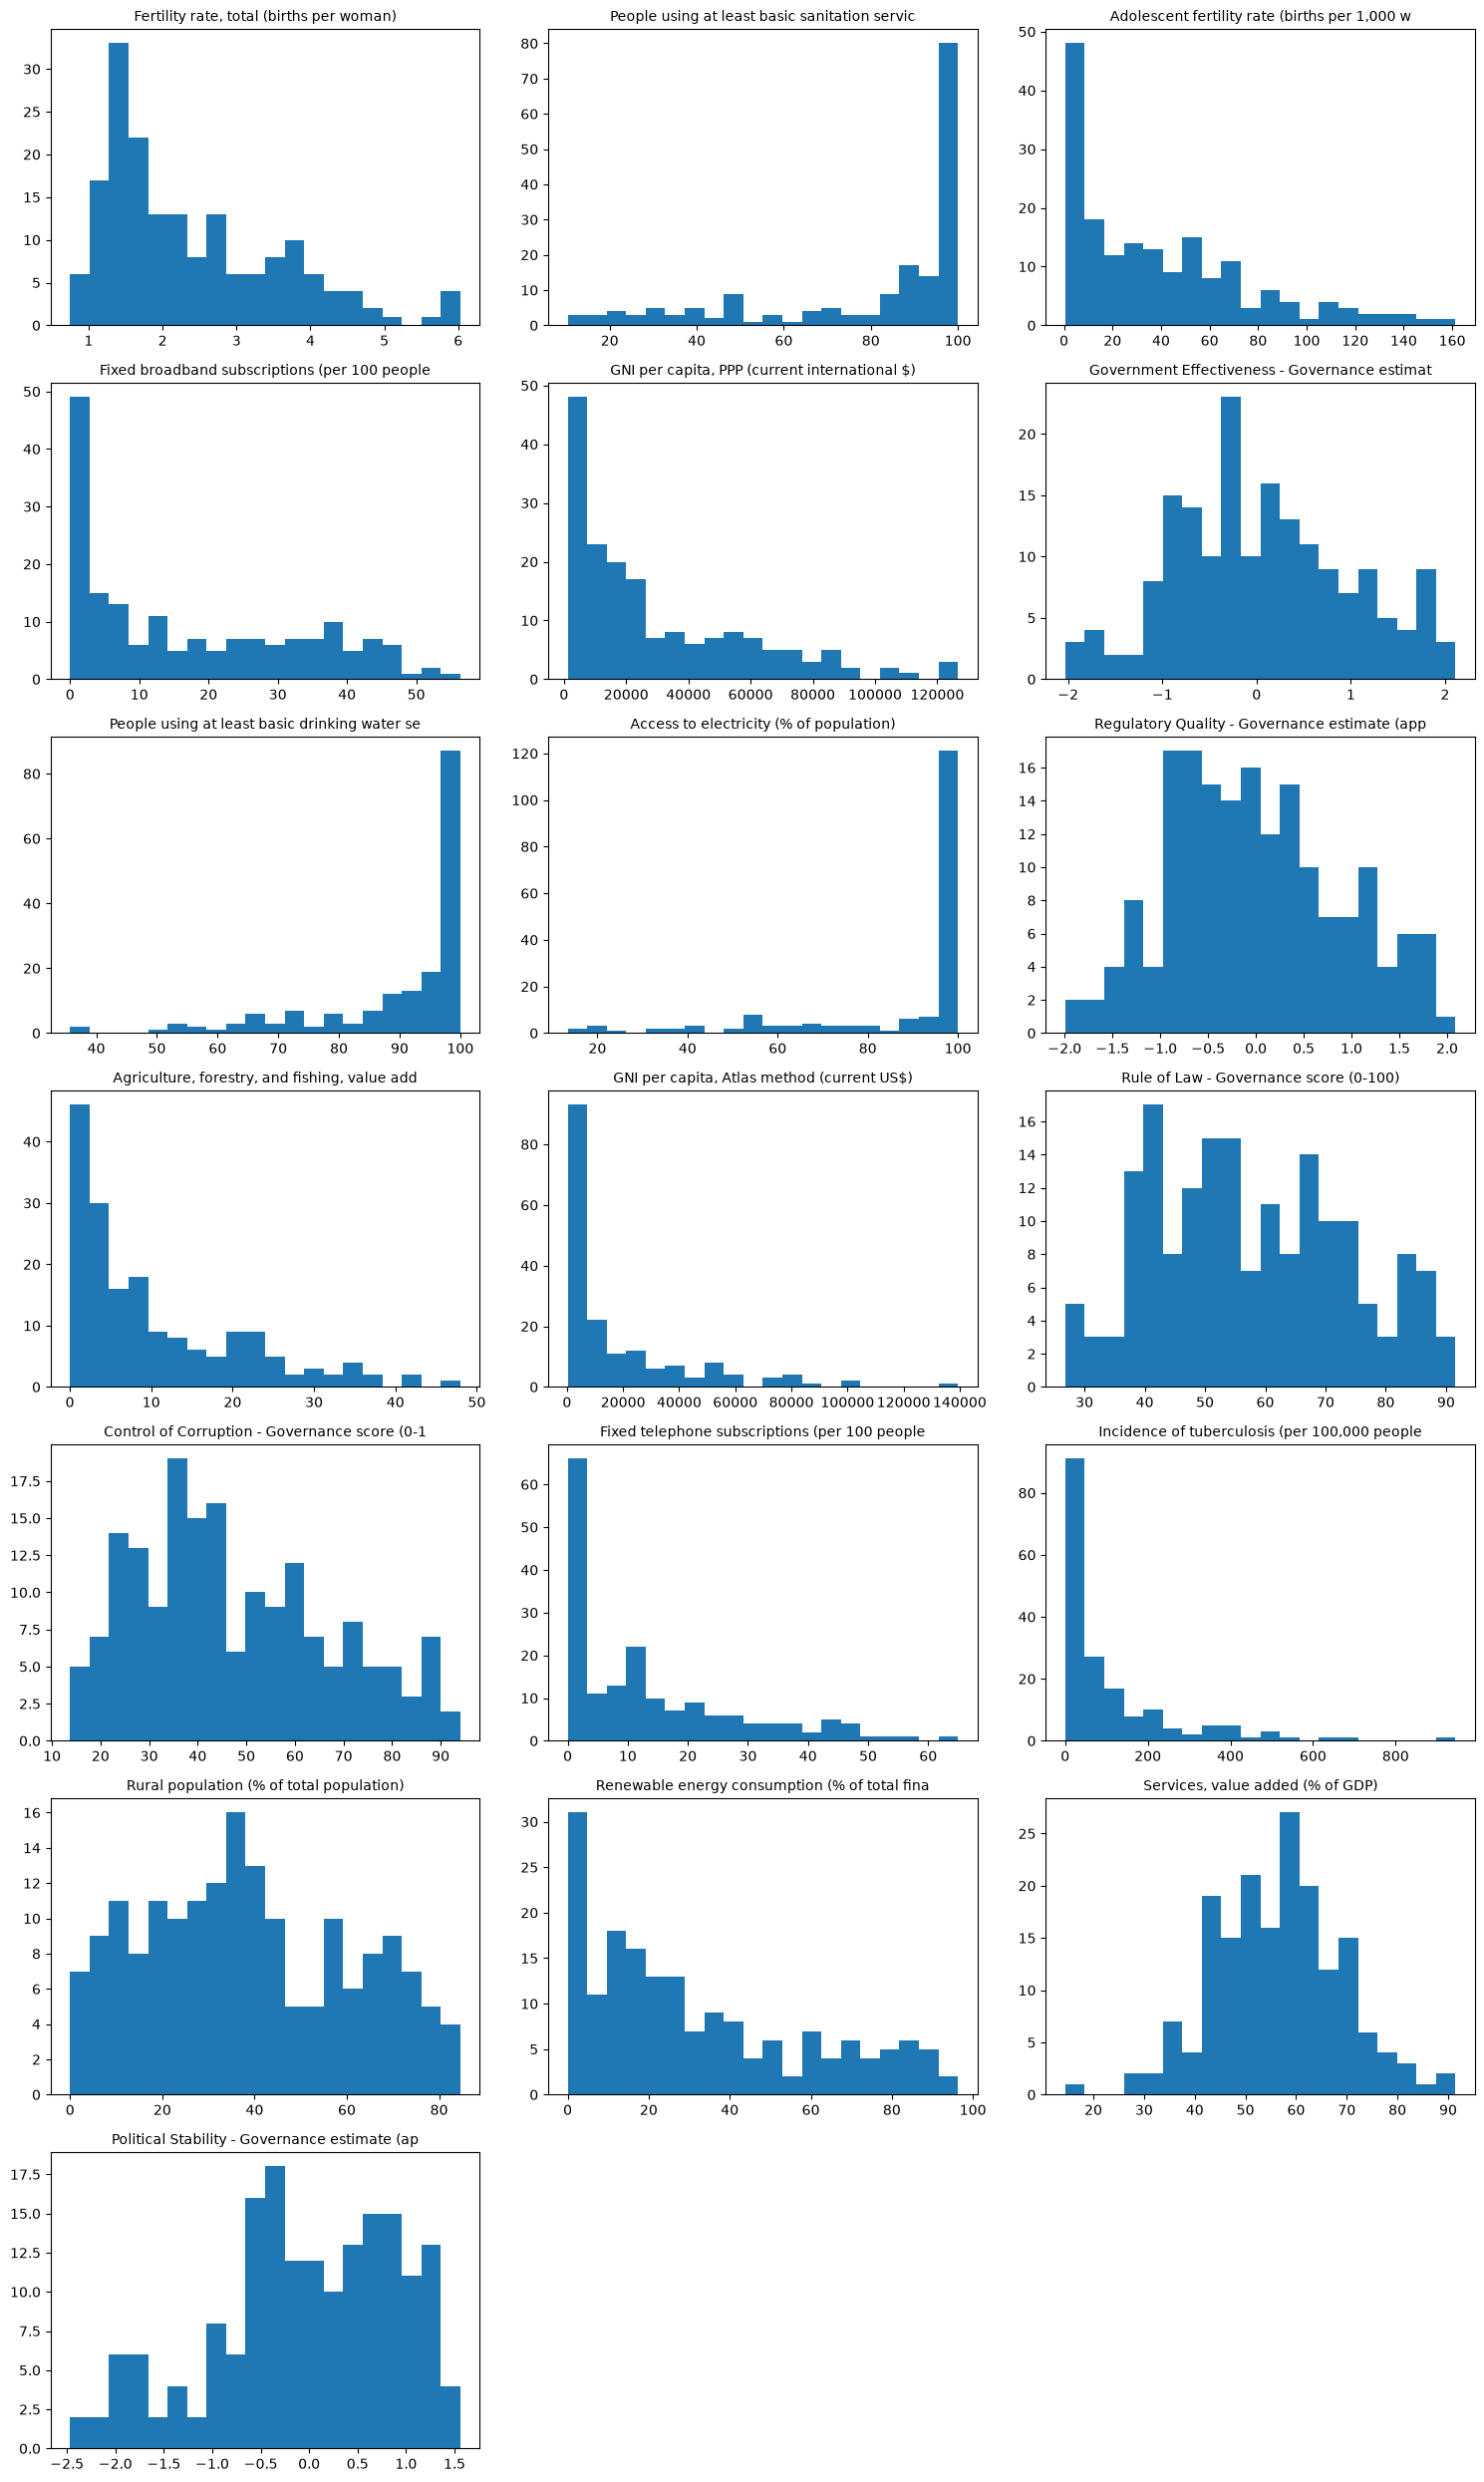

In [33]:
# Histogram of each indicator 
fig, axes = plt.subplots(7, 3, figsize=(15, 25))
axes = axes.flatten()

for i in range(len(kept)):
    code = kept[i]
    axes[i].hist(df_clean[code], bins=20)
    axes[i].set_title(indicator_names[code][:45], fontsize=10)

axes[19].axis('off')
axes[20].axis('off')

plt.tight_layout()
plt.show()

- Many indicators are skewed.Most countries have low fertility, low tuberculosis and low income. A few have very high values.
- Electricity, water and sanitation are close to 100 % in most countries.


### 4.2 Relationship with life expectancy

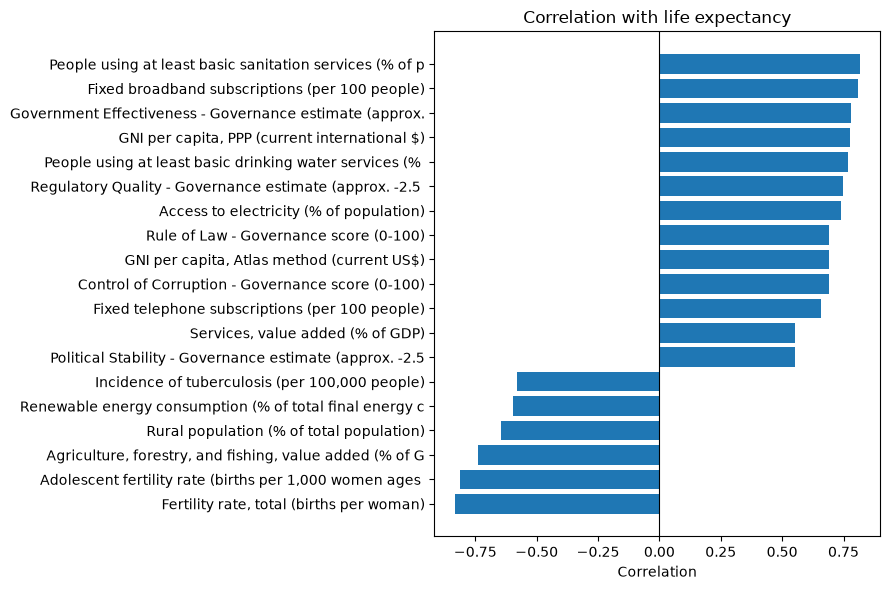

In [34]:
# Correlation of each selected indicator with life expectancy
corr_table = df_clean[kept + ['life_expectancy']].corr()
corr_kept = corr_table['life_expectancy'].drop('life_expectancy')
corr_kept = corr_kept.sort_values()

plt.figure(figsize=(9, 6))
plt.barh(indicator_names[corr_kept.index].str.slice(0, 55), corr_kept.values)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation with life expectancy')
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

- Longer life goes along with sanitation, internet, income, good governance, water and electricity.
- Shorter life goes along with many births, agriculture, a rural population and tuberculosis.
- Somehow more renewable energy goes along with a shorter life.

### 4.3 Summary of the Further Data Understanding

- scaling is needed for the linear regression.
- Basic services, internet, income and governance go along with a longer life, many births and tuberculosis with a shorter one.

## 5. Modeling

### 5.1 Features and target
Features (X): the selected indicators and the region columns.
Target (y): life expectancy in years 

In [35]:
X = df_prepared.drop(columns=['life_expectancy'])
y = df_prepared['life_expectancy']
print('X:', X.shape)
print('y:', y.shape)

X: (177, 26)
y: (177,)


### 5.2 Split into training and test data

- 75 % of the countries are used for training, 25 % for testing.

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)
print('Training countries:', len(X_train))
print('Test countries:', len(X_test))

Training countries: 132
Test countries: 45


### 5.3 Scaling


In [37]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 5.4 Helper function


In [38]:
def print_scores(model, X_train, y_train, X_test, y_test):
    """Print R2 and mean absolute error of a fitted model.

    The scores are shown for the training and the test data.

    Args:
        model: fitted scikit-learn regression model
        X_train, y_train: training features and target
        X_test, y_test: test features and target
    """
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    print('Train R2:', round(r2_score(y_train, train_pred), 2),
          ' Train MAE:', round(mean_absolute_error(y_train, train_pred), 2),
          'years')
    print('Test R2:', round(r2_score(y_test, test_pred), 2),
          ' Test MAE:', round(mean_absolute_error(y_test, test_pred), 2),
          'years')

### 5.5 Linear regression 

In [39]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

print_scores(lin_reg, X_train_scaled, y_train, X_test_scaled, y_test)

Train R2: 0.89  Train MAE: 1.87 years
Test R2: 0.85  Test MAE: 2.15 years


- The linear regression explains about 85 % of the differences between countries.
- On average it is about 2 years off.
- Training and test results are close, so its not overfitting.

### 5.6 Random forest (default settings)

A random forest does not need scaled data, so the original values are used.

In [40]:
forest = RandomForestRegressor(random_state=42)
forest.fit(X_train, y_train)

print_scores(forest, X_train, y_train, X_test, y_test)

Train R2: 0.97  Train MAE: 0.87 years
Test R2: 0.86  Test MAE: 1.96 years


The random forest is almost perfect on the training data but clearly weaker on the test data. 

### 5.7 Random forest with cross-validation

max_depth limits how deep the trees can grow, which helps against overfitting.

The best depth is found with cross-validation on the training data.

In [41]:
for depth in [2, 3, 4, 5, 6, 8, None]:
    model = RandomForestRegressor(max_depth=depth, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=5)
    print('max_depth:', depth, ' R2 scores:', scores.round(2),
          ' mean:', round(scores.mean(), 2))

max_depth: 2  R2 scores: [0.8  0.63 0.87 0.81 0.65]  mean: 0.75
max_depth: 3  R2 scores: [0.8  0.65 0.87 0.83 0.7 ]  mean: 0.77
max_depth: 4  R2 scores: [0.8  0.67 0.86 0.83 0.7 ]  mean: 0.77
max_depth: 5  R2 scores: [0.8  0.68 0.87 0.83 0.71]  mean: 0.78
max_depth: 6  R2 scores: [0.8  0.68 0.87 0.83 0.71]  mean: 0.78
max_depth: 8  R2 scores: [0.8  0.68 0.86 0.83 0.7 ]  mean: 0.77
max_depth: None  R2 scores: [0.8  0.67 0.86 0.83 0.71]  mean: 0.77


- The results differ quite a bit between the 5 parts, so a single split is not very reliable.
- Depths of 5 and 6 work best -> max_depth = 5 is used

In [42]:
# Final random forest 
forest = RandomForestRegressor(max_depth=5, random_state=42)
forest.fit(X_train, y_train)

print_scores(forest, X_train, y_train, X_test, y_test)

Train R2: 0.96  Train MAE: 1.1 years
Test R2: 0.86  Test MAE: 1.92 years


### 5.8 Summary of the Modeling

- Linear regression: explains about 85 %, about 2 years off.
- Random forest: about the same, slightly smaller error.

## 6. Evaluation

### 6.1 Comparison of the two models on the test data

In [43]:
# predict test data
y_pred_lin_reg = lin_reg.predict(X_test_scaled)
y_pred_forest = forest.predict(X_test)

print('Linear regression R2:', round(r2_score(y_test, y_pred_lin_reg), 2),
      ' MAE:', round(mean_absolute_error(y_test, y_pred_lin_reg), 2),
      'years')
print('Random forest R2:', round(r2_score(y_test, y_pred_forest), 2),
      ' MAE:', round(mean_absolute_error(y_test, y_pred_forest), 2),
      'years')

Linear regression R2: 0.85  MAE: 2.15 years
Random forest R2: 0.86  MAE: 1.92 years


- Both models are close. The random forest is slightly better 
- The random forest is used for the next steps.

### 6.2 Which countries live much longer or shorter than predicted?

In [44]:
# Prediction error of each test country
results = pd.DataFrame({
    'Country': country_info.loc[X_test.index, 'Table Name'],
    'Real': y_test.round(1),
    'Predicted': pd.Series(y_pred_forest, index=X_test.index)})
results['Difference'] = (results['Real'] - results['Predicted'])

print('Live longer than predicted:')
print(results.sort_values('Difference', ascending=False).head(5))
print()
print('Live shorter than predicted:')
print(results.sort_values('Difference').head(5))

Live longer than predicted:
                           Country  Real  Predicted  Difference
Country Code                                                   
MWI                         Malawi  67.6  63.184720    4.415280
LBN                        Lebanon  77.9  73.734637    4.165363
CRI                     Costa Rica  81.0  77.281539    3.718461
CHL                          Chile  81.4  78.378307    3.021693
HKG           Hong Kong SAR, China  85.4  82.430801    2.969199

Live shorter than predicted:
                    Country  Real  Predicted  Difference
Country Code                                            
NGA                 Nigeria  54.6  64.799050  -10.199050
GUY                  Guyana  70.3  75.994114   -5.694114
BEN                   Benin  61.0  66.475397   -5.475397
CIV           Côte d'Ivoire  62.1  66.883814   -4.783814
GIN                  Guinea  60.9  64.633250   -3.733250


- Nigeria stands out. People live about 10 years shorter than its indicators suggest
- Guyana, Benin and Guinea also live several years shorter than expected
- Countries like Malawi, Lebanon and Costa Rica live 3-4 years longer than expected

### 6.3 Coefficients of the linear regression

the coefficeints show how many years the prediction changes when an indicator goes up by one standard deviation.

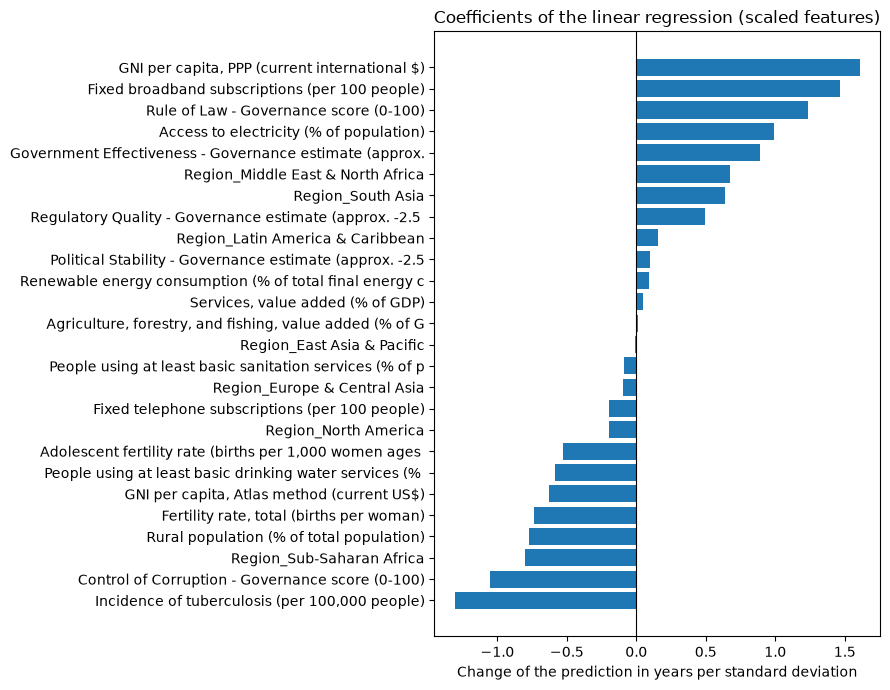

In [45]:
coefficients = pd.Series(lin_reg.coef_, index=X.columns)
column_names = X.columns.to_series()
coefficient_names = column_names.map(indicator_names).fillna(column_names)
coefficients.index = coefficient_names.str.slice(0, 55)
coefficients = coefficients.sort_values()

plt.figure(figsize=(9, 7))
plt.barh(coefficients.index, coefficients.values)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Coefficients of the linear regression (scaled features)')
plt.xlabel('Change of the prediction in years per standard deviation')
plt.tight_layout()
plt.show()

Observation:
- Income, internet, rule of law and electricity push the prediction up.
- Tuberculosis, many births, a rural population and being in Sub-Saharan Africa push it down.

### 6.4 Which indicators drive the prediction of the random forest? 

SHAP values show how much each indicator pushes the prediction for a country up or down

In [46]:
#use the indicator names instead of the codes in the plots
X_test_named = X_test.rename(columns=indicator_names)

explainer = shap.TreeExplainer(forest)
shap_values = explainer.shap_values(X_test_named)

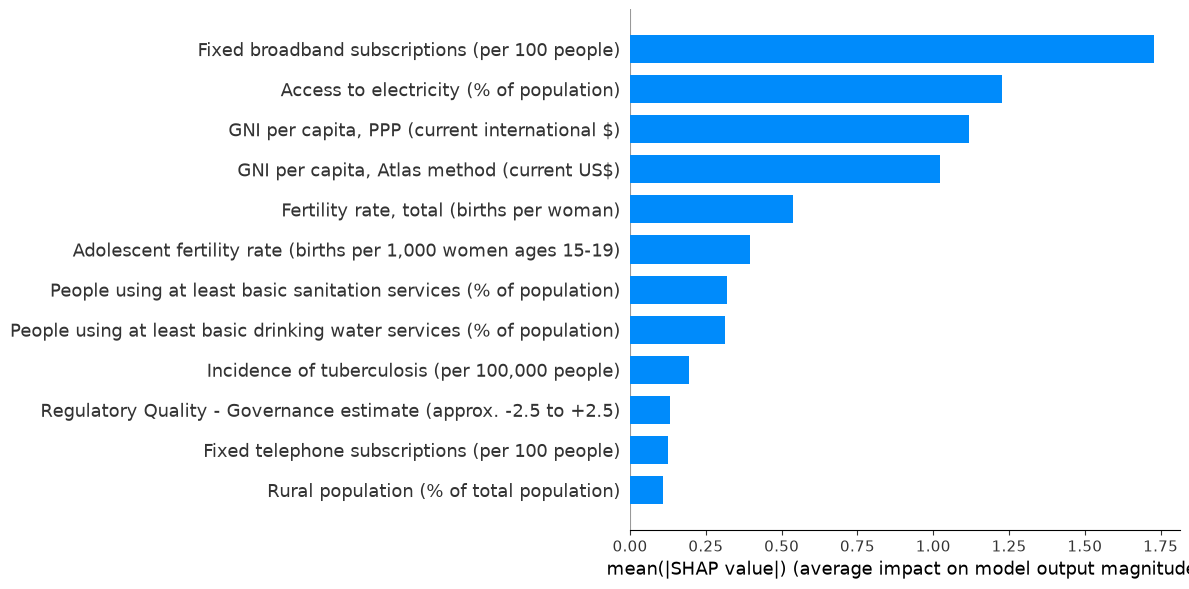

In [47]:
# SHAP value of each feature
shap.summary_plot(shap_values, X_test_named, plot_type='bar', max_display=12, show=False, plot_size=(12, 6))
plt.tight_layout()
plt.show()

- The random forest relies mostly on internet (broadband), electricity, income and the fertility rate.
- Most other indicators play only a small role.

### 6.5 What if scenario: electricity for everyone

Access to electricity is one of the most important indicators for the random forest. What would the model predict if every country with less than 50 % access to electricity had full access? All other indicators stay the same.

In [48]:
# find countries with less than 50 % access to electricity
low_electricity = X[X['EG.ELC.ACCS.ZS'] < 50]
print('Countries with less than 50 % access:', len(low_electricity))

# The same countries but with 100 % access to electricity
scenario = low_electricity.copy()
scenario['EG.ELC.ACCS.ZS'] = 100

# Predictions of the random forest today vs in the scenario
scenario_results = pd.DataFrame({
    'Country': country_info.loc[low_electricity.index, 'Table Name'],
    'Electricity (%)': low_electricity['EG.ELC.ACCS.ZS'].round(0),
    'Predicted today': forest.predict(low_electricity).round(1),
    'Predicted with 100 %': forest.predict(scenario).round(1)})
scenario_results['Gain (years)'] = (scenario_results['Predicted with 100 %']
                                    - scenario_results['Predicted today'])
scenario_results = scenario_results.sort_values('Gain (years)',
                                                ascending=False)

average_gain = scenario_results['Gain (years)'].mean()
print('Average gain:', round(average_gain, 1), 'years')
scenario_results

Countries with less than 50 % access: 14
Average gain: 4.4 years


,Country,Electricity (%),Predicted today,Predicted with 100 %,Gain (years)
Country Code,,,,,
TCD,Chad,13.0,58.1,65.2,7.1
CAF,Central African Republic,18.0,59.0,65.0,6.0
MWI,Malawi,16.0,63.2,68.3,5.1
NER,Niger,21.0,62.5,67.1,4.6
BFA,Burkina Faso,34.0,62.9,67.4,4.5
COD,"Congo, Dem. Rep.",22.0,61.6,66.0,4.4
MOZ,Mozambique,37.0,62.8,67.1,4.3
BDI,Burundi,20.0,63.4,67.5,4.1
LBR,Liberia,35.0,63.2,67.2,4.0


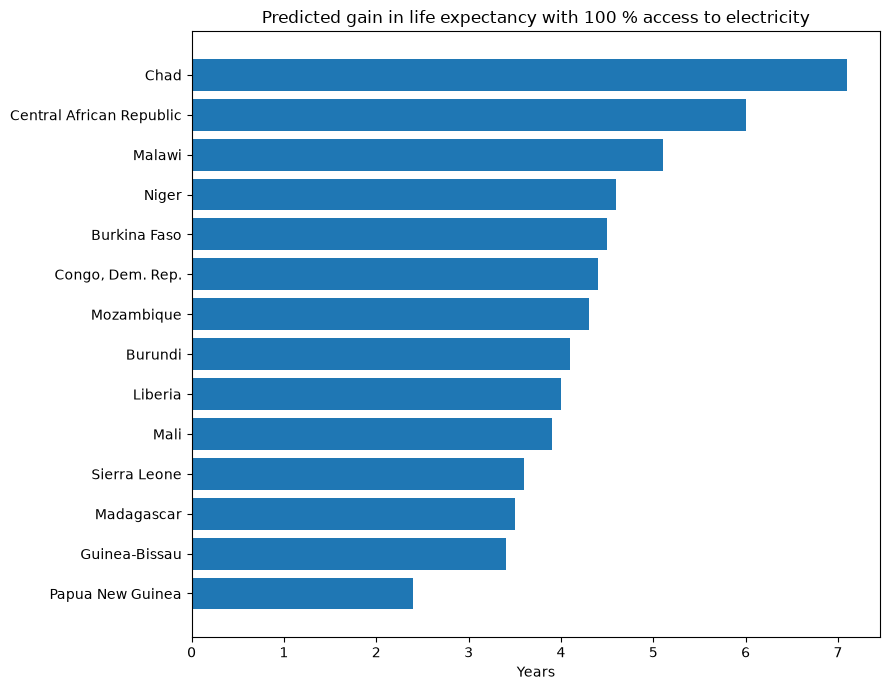

In [49]:
# Bar charts
plt.figure(figsize=(9, 7))
plt.barh(scenario_results['Country'], scenario_results['Gain (years)'])
plt.gca().invert_yaxis()
plt.title('Predicted gain in life expectancy with 100 % access to electricity')
plt.xlabel('Years')
plt.tight_layout()
plt.show()

Findings:
- 14 countries have less than 50 % access to electricity, all except Papua New Guinea in Sub-Saharan Africa.
- With full access the model predicts on average about 4 years more.
- The biggest gains are in Chad (about +7 years) and the Central African Republic (about +6), the countries with the lowest access today.
- With full access all predictions stay between about 65 and 68 years. Still well below the world average of about 74. Electricity alone does not close the gap, the other indicators still hold these countries back.

### 6.6 Summary of the Evaluation

- Both models predict life expectancy with an average error of around 2 years.
- The key indicators are internet, electricity, income and the fertility rate.
- Some countries (e.g. Nigeria) live much shorter than their indicators suggest.
- In the scenario, full access to electricity would raise the predicted life expectancy by about 4 years in the countries with the lowest access
- the model finds relationships in the data but strong relationship does not prove that an indicator causes a longer life.

### 6.7 Answers to the questions

1. Which indicators are most important for predicting life expectancy, and how do they influence the prediction?
- Internet (fixed broadband), access to electricity, income (GNI per capita) and the fertility rate.
- More internet, electricity and income go along with a higher predicted life expectancy, more births with a lower one.

2. What unusual or surprising insights can be found?
- Nigeria lives about 10 years shorter than its indicators suggest. Countries like Guyana, Benin and Guinea also live several years shorter.
- Malawi, Lebanon and Costa Rica live about 4 years longer than predicted.
- Surprisingly more renewable energy goes along with a shorter life .

3. How accurately can a model predict the life expectancy of a country?
- Both models are on average about 2 years off and explain about 85 % of the differences between countries (random forest: R2 0.86, MAE 1.9 years and linear regression: R2 0.85, MAE 2.2 years)

4. What would the model predict if every country with less than 50 % access to electricity had full access?
- For these 14 countries the predicted life expectancy rises by about 4 years on average. In Chad by about 7 years (section 6.5).
- The predictions still stay between about 65 and 68 years which is below the average country (74 years). Electricity alone does not really close the gap.